# Data audit and cleaning

Read the source audit from overview to supporting evidence. Pending matches are **not** part of the included cohort. The current verified audit has no pending matches; Stage 04 separately checks resource eligibility.

This notebook reads verified audit reports by default. Updating charts does not rerun cleaning or train models.


In [10]:
from pathlib import Path
import importlib
import json
import sys
import pandas as pd
from IPython.display import display

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / 'config' / 'experiment.yaml').is_file()
             and (p / 'src' / 'data_preparation.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the project directory.')
sys.path.insert(0, str(ROOT / 'src'))
import data_preparation
importlib.reload(data_preparation)
OUTPUT = ROOT / 'outputs' / '01_data_audit_and_cleaning'

# True regenerates audit reports only. False reads existing verified reports.
RUN_AUDIT = False
# Enable only after reviewing the audit; exports the verified cohort for Stage 02.
EXPORT_CLEAN_DATA = False
print('Project:', ROOT)
print('Python:', sys.executable)
print('pandas:', pd.__version__)

import matplotlib.pyplot as plt
import audit_visualisation as viz
importlib.reload(viz)
SAVE_FIGURES = True  # Presentation PNGs only; never exports the clean dataset.
FIGURES = OUTPUT / 'figures'

def show_figure(fig, name):
    if SAVE_FIGURES:
        viz.save_figure(fig, FIGURES, name)
    display(fig)
    plt.close(fig)


Project: D:\T20_Project\T20_Project_3.0
Python: d:\T20_Project\T20_Project_3.0\.venv\Scripts\python.exe
pandas: 2.3.3


## 1. Audit overview

The three decisions below are mutually exclusive. Percentages use all audited matches as the denominator. Results remain provisional while matches are pending review.


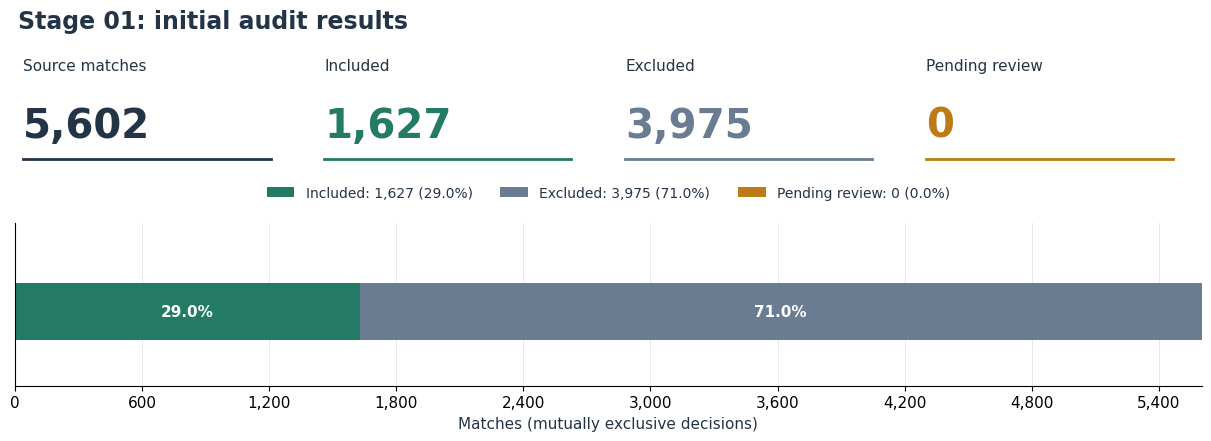

Verified included delivery events: 385,786
Pending matches: 0.
Audit snapshot (UTC): 2026-10-01T08:08:21.517521+00:00


In [11]:
if RUN_AUDIT:
    data_preparation.run(ROOT, export_clean=False)
summary = data_preparation.verified_audit(ROOT)
config = data_preparation.read_config(ROOT)

def read_report(name):
    return pd.read_csv(OUTPUT / name, keep_default_na=False)

decisions = read_report('match_decisions.csv')
reasons = read_report('reason_counts.csv')
included = read_report('included_matches.csv')
excluded = read_report('excluded_matches.csv')
pending = read_report('pending_matches.csv')
innings_audit = read_report('innings_audit.csv')
corrections = read_report('corrections.csv')
assert decisions['match_id'].is_unique
assert len(decisions) == len(included) + len(excluded) + len(pending)
assert len(decisions) == summary['audited_matches']
assert int(included['csv_events'].sum()) == summary['included_events']
for status, frame in [('included', included), ('excluded', excluded), ('pending_review', pending)]:
    assert len(frame) == summary['match_counts'][status]
show_figure(viz.overview_figure(summary), 'audit_overview')
print(f"Verified included delivery events: {summary['included_events']:,}")
print(f"Pending matches: {len(pending):,}." + (' Review before freezing the final cohort.' if len(pending) else ''))
print('Audit snapshot (UTC):', summary['created_utc'])


## 2. Reasons for exclusion

These are research-scope exclusions, not a count of corrupt matches. **Reasons overlap**: a tied Super Over match can appear in both categories. The largest category includes teams outside the agreed population.


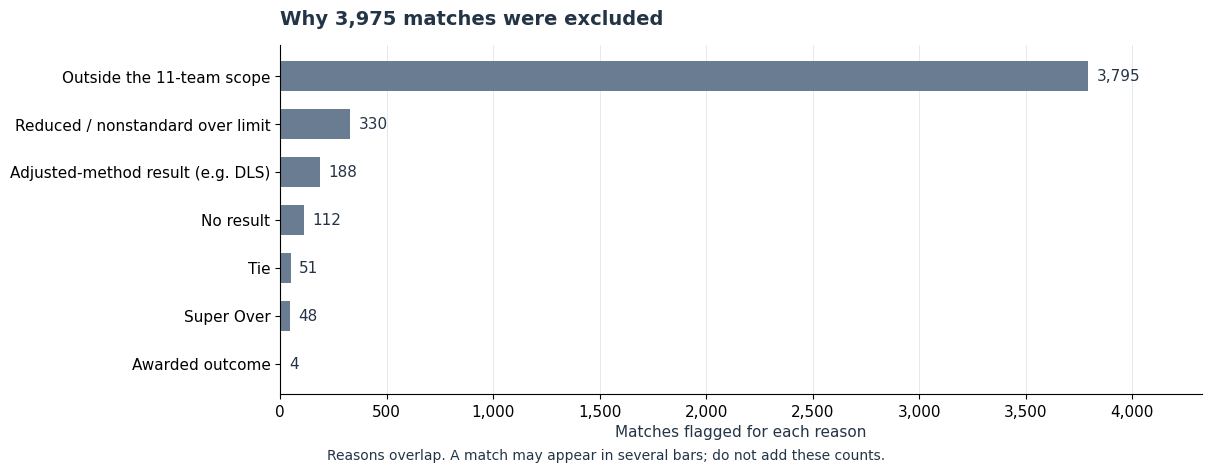

match_id,match_date,gender,exclusion_reasons
237242,2006-02-16,male,super_over;tie
251487,2006-12-22,male,adjusted_method;reduced_or_nonstandard_overs
287854,2007-09-12,male,outside_team_scope
287855,2007-09-12,male,outside_team_scope
287860,2007-09-14,male,outside_team_scope
287862,2007-09-14,male,super_over;tie
306987,2007-09-01,male,outside_team_scope
306991,2007-09-04,male,outside_team_scope
319112,2007-12-16,male,reduced_or_nonstandard_overs
319142,2008-06-20,male,reduced_or_nonstandard_overs


In [12]:
show_figure(viz.exclusion_figure(reasons, len(excluded)), 'exclusion_reasons')
display(viz.table(excluded[['match_id', 'match_date', 'gender', 'exclusion_reasons']].head(15),
                  'Exclusion examples (first 15; full list in excluded_matches.csv)', collapsed=True))


## 3. Included cohort

Counts describe the currently included matches only, not all T20 internationals. Stage 01 does not create the training, validation or test split; Stage 06 owns that split.


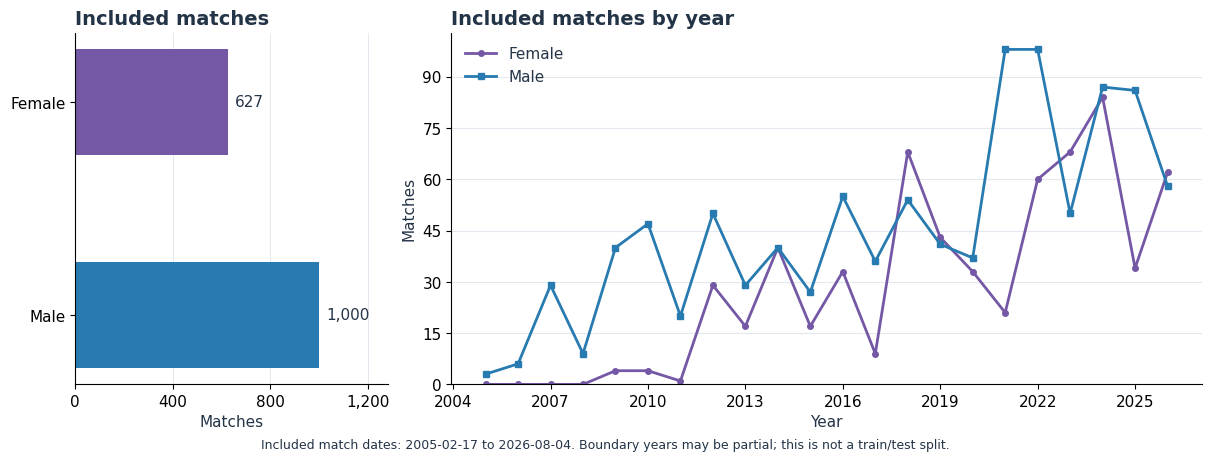

Gender,Matches,Delivery events
female,627,147722
male,1000,238064


In [13]:
show_figure(viz.cohort_figure(included), 'included_cohort')
gender_counts, annual_counts, first_date, last_date = viz.cohort_tables(included)
display(viz.table(gender_counts.reset_index().rename(columns={'gender': 'Gender', 'matches': 'Matches', 'events': 'Delivery events'}),
                  'Exact cohort counts', collapsed=True))


## 4. Injury-related completion and pending matches

A normal innings may end with fewer than ten dismissals when no further batting pair is available. Verified cases require eleven distinct roster identities, consistent absence and retirement evidence, observed returns, and exhaustion only at the final event. Injury never adds a wicket.

The table below is retrospective audit evidence. Full-innings absence metadata has no event timestamp and must not be treated as pre-match or pre-delivery availability information.


In [14]:
resolved_endings = innings_audit.loc[innings_audit['audit_completion_basis'].eq('no_available_batting_pair')
                                   & innings_audit['match_id'].isin(included['match_id'])]
print(f"Verified no-pair endings: {len(resolved_endings):,}")
if not resolved_endings.empty:
    display(viz.table(resolved_endings[['match_id', 'match_innings', 'batting_team', 'final_wickets',
                                      'absent_hurt', 'audit_unreturned_retirements', 'audit_remaining_batters']]
                      .rename(columns={'match_id': 'Match ID', 'match_innings': 'Innings', 'batting_team': 'Batting team',
                                       'final_wickets': 'Dismissals', 'absent_hurt': 'Absent hurt',
                                       'audit_unreturned_retirements': 'Retired, not returned',
                                       'audit_remaining_batters': 'Remaining batter'}),
                      'Verified injury-related endings', collapsed=True))
if pending.empty:
    print('No matches currently require review.')
else:
    display(viz.table(viz.pending_table(pending), 'Pending matches'))


Verified no-pair endings: 20


Match ID,Innings,Batting team,Dismissals,Absent hurt,"Retired, not returned",Remaining batter
426723,2,New Zealand,9,"[""AJ Redmond""]",[],"[""SE Bond""]"
560921,2,New Zealand,8,"[""RM Hira""]","[""LRPL Taylor""]","[""DAJ Bracewell""]"
682955,2,New Zealand,9,"[""CJ Anderson""]",[],"[""MJ McClenaghan""]"
682991,2,Ireland,9,"[""CNIM Joyce""]",[],"[""AJ Kenealy""]"
1115800,2,West Indies,9,"[""SD Hope""]",[],"[""AR Nurse""]"
1122730,2,Sri Lanka,9,"[""AD Mathews""]",[],"[""N Pradeep""]"
1140069,2,West Indies,9,"[""V Permaul""]",[],"[""KMA Paul""]"
1142913,2,Zimbabwe,9,"[""KM Jarvis""]",[],"[""J Nyumbu""]"
1150549,2,Australia,9,"[""AJ Healy""]",[],"[""EA Perry""]"
1173063,2,West Indies,9,[],"[""SR Taylor""]","[""SC Selman""]"


No matches currently require review.


## 5. Special cases and recorded changes

Examples below are selected from the current audit. Documented miscounts alone do not justify exclusion. Pre-innings penalties affect the starting score; post-innings penalties affect official totals and targets, not an earlier delivery. Temporary retirement is not a dismissal.

Coordinate normalization is not evidence that thousands of delivery events are wrong: `ball` identifies the event within its source over, including wides and no-balls. Original coordinates remain preserved. Change counts below count **fields**, not unique events or matches.


In [15]:
display(viz.table(viz.special_case_table(innings_audit, decisions, corrections), 'Source-verified examples'))
changes = corrections.groupby(['field', 'reason']).size().rename('Field changes').reset_index()
display(viz.table(changes, 'Recorded field changes', collapsed=True))
display(viz.table(corrections.head(20), 'Correction evidence (first 20; full list in corrections.csv)', collapsed=True))
missing = read_report('missing_values.csv')
display(viz.table(missing.loc[missing['missing_count'].gt(0)], 'Raw-source missing values', collapsed=True))
display(viz.table(decisions.loc[decisions['warnings'].ne(''), ['match_id', 'status', 'warnings']], 'Metadata warnings', collapsed=True))


Case,Match ID,Evidence,Handling
Documented miscount,287871,"Innings 2: {""12"": {""balls"": 7, ""umpire"": ""MR Benson""}}",Retained after event verification
Pre-innings penalty,1150537,Innings 2: 10,Included in the initial innings score
Post-innings penalty,1138202,Innings 1: 5,"Official total / target adjusted, not earlier deliveries"
Temporary retirement,560921,retired hurt,Retirement recorded without adding a wicket
No available batting pair,426723,9 dismissals; one available batter remains,"Normal completion verified from roster, absence and retirement evidence"


field,reason,Field changes
ball,source_verified_event_coordinate,44176
innings_score,source_penalty_aware_cumulative_score,181
innings_wickets,source_retirement_aware_cumulative_wickets,84
is_wicket,explicit_source_retirement,5
player_out,explicit_source_retirement,31
wicket_kind,explicit_source_retirement,31


match_id,source_row,field,original_value,canonical_value,reason,evidence
211028,1121187,ball,6,7,source_verified_event_coordinate,211028.json:innings=1;over=0;event=7
211028,1121191,ball,3,4,source_verified_event_coordinate,211028.json:innings=1;over=1;event=4
211028,1121192,ball,4,5,source_verified_event_coordinate,211028.json:innings=1;over=1;event=5
211028,1121193,ball,5,6,source_verified_event_coordinate,211028.json:innings=1;over=1;event=6
211028,1121194,ball,6,7,source_verified_event_coordinate,211028.json:innings=1;over=1;event=7
211028,1121209,ball,2,3,source_verified_event_coordinate,211028.json:innings=1;over=4;event=3
211028,1121210,ball,3,4,source_verified_event_coordinate,211028.json:innings=1;over=4;event=4
211028,1121211,ball,4,5,source_verified_event_coordinate,211028.json:innings=1;over=4;event=5
211028,1121212,ball,4,6,source_verified_event_coordinate,211028.json:innings=1;over=4;event=6
211028,1121213,ball,5,7,source_verified_event_coordinate,211028.json:innings=1;over=4;event=7


source,column,missing_count,rows
deliveries,date,1266835,1266835
deliveries,player_out,1196477,1266835
deliveries,wicket_kind,1196477,1266835
deliveries,match_winner,22633,1266835
deliveries,match_referee,284451,1266835
deliveries,tv_umpire,776339,1266835
deliveries,reserve_umpire,216037,1266835
deliveries,umpire_1,94254,1266835
deliveries,umpire_2,95325,1266835


match_id,status,warnings
894293,included,info_overs_conflict_checked_against_explicit_target_and_events
1213874,included,info_overs_conflict_checked_against_explicit_target_and_events
1213875,included,info_overs_conflict_checked_against_explicit_target_and_events
1334415,included,info_overs_conflict_checked_against_explicit_target_and_events
1334416,included,info_overs_conflict_checked_against_explicit_target_and_events
1334417,included,info_overs_conflict_checked_against_explicit_target_and_events
1334418,excluded,info_overs_conflict_checked_against_explicit_target_and_events
1430820,included,info_overs_conflict_checked_against_explicit_target_and_events
1430821,included,info_overs_conflict_checked_against_explicit_target_and_events
1448360,included,info_overs_conflict_checked_against_explicit_target_and_events


## 6. Scope, provenance and data checks

The original example defines the eleven-team population and complete-match intent. Detailed source-verification safeguards are research decisions, not verbatim overview requirements. Normal all-out and successful-chase endings need not reach 120 legal balls. Adjusted-method results, reduced-over formats, ties, no-results, awards and Super Overs are outside the main study.

CSV event order is verified against JSON. Empty dismissal fields without a wicket are expected. The raw delivery `date` field is empty; checked match-level dates supply `match_date`. Core missing values are not filled with zero.

The preview contains event outcomes and post-event counters. Stage 02 must explicitly construct pre-delivery features. Final outcomes, final totals and future miscount details are not live predictors. Lineup reconstruction belongs to Stage 04, not an automatic Stage 01 exclusion.


In [16]:
display(viz.table(pd.DataFrame({'Team': config['team_scope']}), 'Agreed team scope', collapsed=True))
sources = pd.DataFrame([{'Source': name, 'Path': path, 'Exists': (ROOT / path).is_file(),
                         'Bytes': (ROOT / path).stat().st_size if (ROOT / path).is_file() else None}
                        for name, path in config['paths'].items()])
display(viz.table(sources, 'Source files', collapsed=True))
preview = read_report('clean_event_preview.csv')
display(viz.table(preview[['match_id', 'source_row', 'match_innings', 'event_sequence', 'over', 'ball',
                         'runs_total', 'legal_delivery', 'innings_score', 'innings_wickets']],
                  'Verified event preview (not a published dataset)', collapsed=True))
print('Input and report SHA-256 checks passed. Audit identity:', summary['audit_id'])
if SAVE_FIGURES:
    data_preparation.write_json(FIGURES / 'figure_manifest.json', {
        'audit_id': summary['audit_id'], 'audit_created_utc': summary['created_utc'],
        'visualisation_sha256': data_preparation.sha256(ROOT / 'src' / 'audit_visualisation.py'),
        'figures': ['audit_overview.png', 'exclusion_reasons.png', 'included_cohort.png'],
        'note': 'Presentation figures only; source audit reports and cleaning decisions are separate artifacts.'})
    print('Presentation figures saved to:', FIGURES)


Team
Sri Lanka
India
South Africa
West Indies
England
New Zealand
Australia
Ireland
Pakistan
Zimbabwe


Source,Path,Exists,Bytes
matches,data/raw/t20i_matches_data.csv,True,265865
deliveries,data/raw/t20i_deliveries_data.csv,True,262283194
female_json,data/raw/cricsheet/t20s_female_json.zip,True,8536330
male_json,data/raw/cricsheet/t20s_male_json.zip,True,14214702


match_id,source_row,match_innings,event_sequence,over,ball,runs_total,legal_delivery,innings_score,innings_wickets
211028,1121181,1,1,0,1,0,1,0,0
211028,1121182,1,2,0,2,1,1,1,0
211028,1121183,1,3,0,3,0,1,1,0
211028,1121184,1,4,0,4,0,1,1,0
211028,1121185,1,5,0,5,0,1,1,0
211028,1121186,1,6,0,6,1,0,2,0
211028,1121187,1,7,0,7,2,1,4,0
211028,1121188,1,8,1,1,0,1,4,0
211028,1121189,1,9,1,2,0,1,4,0
211028,1121190,1,10,1,3,1,0,5,0


Input and report SHA-256 checks passed. Audit identity: 69804d9698fb8c81c6c47d3965c293fcef455d7fbe16e9c187574b0e8496b99f
Presentation figures saved to: D:\T20_Project\T20_Project_3.0\outputs\01_data_audit_and_cleaning\figures


## 7. Clean-data handoff

The clean dataset contains only included matches and retains the verified source event order. Its manifest links the published data to the audit inputs, code and results. Raw source files are read-only. Execution controls are documented in `docs/current_workflow.md`.

Before downstream processing, verify that the clean-export manifest identifies the same audit as the audit reports.


In [17]:
if EXPORT_CLEAN_DATA:
    summary = data_preparation.run(ROOT, export_clean=True)
    print('Clean data published to:', ROOT / 'data' / 'processed' / 'matches')

manifest_path = ROOT / 'data' / 'processed' / 'matches' / 'manifest.json'
if manifest_path.exists():
    exported_manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    print('Clean export status:', exported_manifest.get('status'))
    print('Clean export matches this audit:',
          exported_manifest.get('status') == 'complete'
          and exported_manifest.get('audit_id') == summary['audit_id'])


Clean export status: complete
Clean export matches this audit: True
